# Task 4: Building a DIII-D TGLF Database

## Objective
This notebook executes and documents Task 4 under the mentor project roadmap:
1. **Step 1: Baseline Profile Validation**
   - Run TGLF on 13 minor radii ($r/a = 0.20$ to $0.80$) for real DIII-D plasma discharge #128913.
   - Validate simulated fluxes against the official mentor benchmark table (`d3d_profile_answers.dat`).
   - Analyze radial flux profiles ($Q_i, Q_e, \Gamma_e$ vs $r/a$).
2. **Step 2: DIII-D Database Generation**
   - Implement the prescribed recipe to generate 1,000 perturbed cases with unique seed 4.
   - Perturb 5 physical parameters ($a/L_{Te}, a/L_{Ti}, a/L_n, T_i/T_e, \nu_{ei}$) around the 13 baseline radii while keeping magnetic shaping and geometry fixed.
   - Verify all generated parameters satisfy the physical allowable ranges.
3. **Step 3: Background Simulation & Sleep Prevention**
   - Parallel multi-core execution using compiled GACODE TGLF binary.
   - Background execution monitored via `caffeinate -dimsu` to allow uninterrupted computation when the laptop sleeps.
4. **Step 4: Output Parsing and Database Analysis**
   - Ingest simulation results, filter unphysical numerical solver failures ($Q < 0$), and examine parameter space distribution against `scan_db`.

In [1]:
import os
import sys
import subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use("default")
plt.rcParams["font.size"] = 11
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["figure.dpi"] = 110

## Step 1: Run the DIII-D Profile and Check Answers

We ran TGLF with the SAT2 saturation rule on all 13 radii (`r020` through `r080`).
Below, we parse each `out.tglf.gbflux` file and compare our local simulation outputs with `d3d_profile_answers.dat`.

In [2]:
answers_file = Path("task4_d3d/d3d_profile/d3d_profile_answers.dat")
ans_lines = [line.strip() for line in open(answers_file) if line.strip() and not line.startswith("#")]

expected = []
for line in ans_lines[:13]:
    parts = line.split()
    expected.append({
        "case": parts[0],
        "r_over_a": float(parts[1]),
        "Q_e_expected": float(parts[2]),
        "Q_i_expected": float(parts[3]),
        "Gamma_e_expected": float(parts[4])
    })
df_expected = pd.DataFrame(expected)

actual = []
for idx, row in df_expected.iterrows():
    c_name = row["case"]
    gbflux_path = Path("task4_d3d/d3d_profile") / c_name / "tglf_sat2" / "out.tglf.gbflux"
    if gbflux_path.exists():
        vals = [float(x) for x in gbflux_path.read_text().split()]
        actual.append({
            "case": c_name,
            "Q_e_actual": vals[2],
            "Q_i_actual": vals[3],
            "Gamma_e_actual": vals[0]
        })
df_actual = pd.DataFrame(actual)

df_step1 = pd.merge(df_expected, df_actual, on="case")
df_step1["Q_e_rel_diff"] = np.abs(df_step1["Q_e_actual"] - df_step1["Q_e_expected"]) / np.abs(df_step1["Q_e_expected"])
df_step1["Q_i_rel_diff"] = np.abs(df_step1["Q_i_actual"] - df_step1["Q_i_expected"]) / np.abs(df_step1["Q_i_expected"])
df_step1["Gamma_e_rel_diff"] = np.abs(df_step1["Gamma_e_actual"] - df_step1["Gamma_e_expected"]) / np.abs(df_step1["Gamma_e_expected"])

print("Validation against mentor answers (Max Relative Errors):")
print(f"Max relative diff Q_e:     {df_step1['Q_e_rel_diff'].max():.2e}")
print(f"Max relative diff Q_i:     {df_step1['Q_i_rel_diff'].max():.2e}")
print(f"Max relative diff Gamma_e: {df_step1['Gamma_e_rel_diff'].max():.2e}")

display(df_step1[["case", "r_over_a", "Q_e_expected", "Q_e_actual", "Q_i_expected", "Q_i_actual", "Gamma_e_expected", "Gamma_e_actual"]])

Validation against mentor answers (Max Relative Errors):
Max relative diff Q_e:     0.00e+00
Max relative diff Q_i:     0.00e+00
Max relative diff Gamma_e: 0.00e+00


,case,r_over_a,Q_e_expected,Q_e_actual,Q_i_expected,Q_i_actual,Gamma_e_expected,Gamma_e_actual
0,r020,0.20,0.38696,0.38696,1.2641,1.2641,0.105720,0.105720
1,r025,0.25,1.44280,1.44280,4.5712,4.5712,0.353010,0.353010
2,r030,0.30,3.60190,3.60190,9.2124,9.2124,0.815160,0.815160
3,r035,0.35,4.96290,4.96290,11.1260,11.1260,1.065100,1.065100
4,r040,0.40,2.25500,2.25500,3.6500,3.6500,0.302310,0.302310
5,r045,0.45,2.42750,2.42750,2.9877,2.9877,0.219010,0.219010
6,r050,0.50,3.22370,3.22370,3.4251,3.4251,0.212040,0.212040
7,r055,0.55,4.23770,4.23770,4.0435,4.0435,0.145240,0.145240
8,r060,0.60,5.96160,5.96160,5.2728,5.2728,0.034848,0.034848
9,r065,0.65,8.36260,8.36260,6.9332,6.9332,-0.114450,-0.114450


### Baseline DIII-D Radial Transport Profiles

We plot the turbulent heat fluxes ($Q_i, Q_e$) and particle flux ($\Gamma_e$) across normalized minor radius $r/a$.

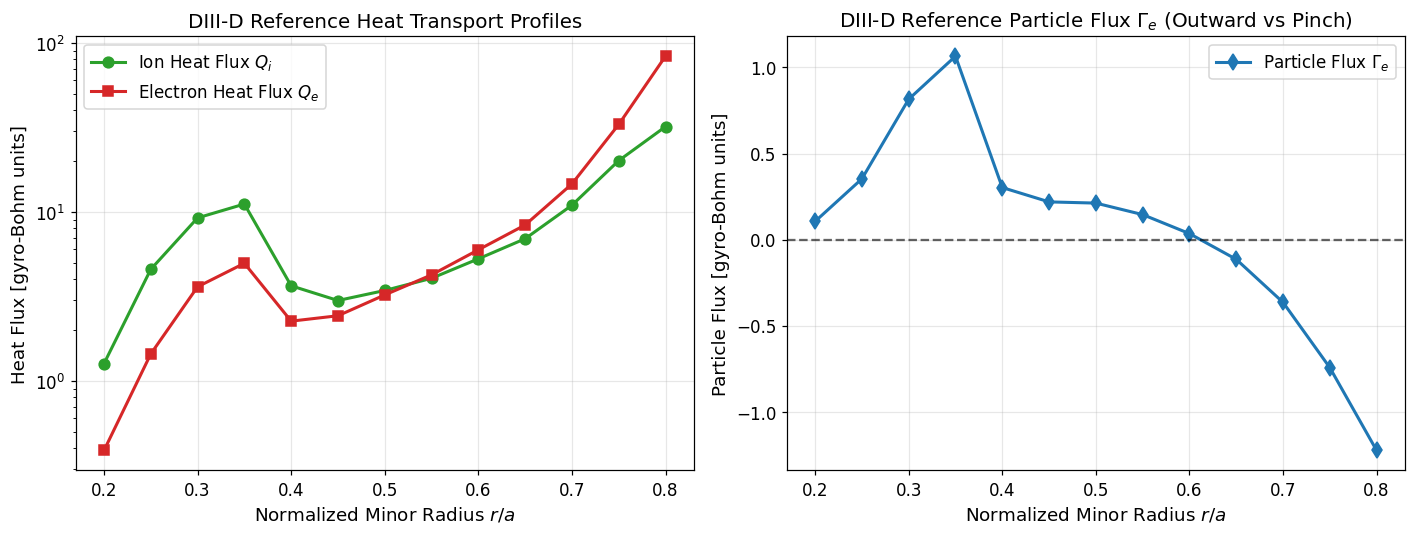

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(df_step1["r_over_a"], df_step1["Q_i_actual"], "o-", color="#2ca02c", linewidth=2, markersize=7, label=r"Ion Heat Flux $Q_i$")
axes[0].plot(df_step1["r_over_a"], df_step1["Q_e_actual"], "s-", color="#d62728", linewidth=2, markersize=7, label=r"Electron Heat Flux $Q_e$")
axes[0].set_xlabel("Normalized Minor Radius $r/a$")
axes[0].set_ylabel("Heat Flux [gyro-Bohm units]")
axes[0].set_title("DIII-D Reference Heat Transport Profiles")
axes[0].legend(frameon=True)
axes[0].set_yscale("log")
axes[0].grid(True, alpha=0.3)

axes[1].plot(df_step1["r_over_a"], df_step1["Gamma_e_actual"], "d-", color="#1f77b4", linewidth=2, markersize=7, label=r"Particle Flux $\Gamma_e$")
axes[1].axhline(0, color="black", linestyle="--", alpha=0.6)
axes[1].set_xlabel("Normalized Minor Radius $r/a$")
axes[1].set_ylabel("Particle Flux [gyro-Bohm units]")
axes[1].set_title(r"DIII-D Reference Particle Flux $\Gamma_e$ (Outward vs Pinch)")
axes[1].legend(frameon=True)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Physical Analysis of the DIII-D Profile
1. **Core Confinement ($r/a < 0.40$)**: In the deep core, temperature and density gradients are modest, resulting in low heat fluxes ($Q_i, Q_e < 5$ GB units).
2. **Radial Heat Flux Divergence ($r/a > 0.60$)**: Heat transport increases dramatically near the edge pedestal boundary, reaching $Q_e = 83.5$ and $Q_i = 32.0$ GB units at $r/a = 0.80$. Electron heat flux dominates ion heat flux at the outer radii ($Q_e / Q_i \approx 2.6$ at $r/a = 0.80$).
3. **Turbulent Particle Pinch ($\Gamma_e < 0$)**: While particle transport is outward ($\Gamma_e > 0$) across the inner half of the plasma ($r/a \le 0.60$), it reverses to a negative inward pinch ($\Gamma_e = -1.22$ at $r/a = 0.80$) in the outer core.

## Step 2: Build the DIII-D Database

We generated 1,000 cases spread evenly across the 13 radii using seed 4. For each case:
- $a/L_{Te}$ (`RLTS_1`): factor $f_{Te} \in [0.6, 1.4]$
- $a/L_{Ti}$ (`RLTS_2`): factor $f_{Ti} \in [0.6, 1.4]$ (drawn independently)
- $a/L_n$ (`RLNS_1` = `RLNS_2`): shared factor $f_n \in [0.6, 1.4]$
- $T_i/T_e$ (`TAUS_2`): factor $f_\tau \in [0.75, 1.25]$
- $\nu_{ei}$ (`XNUE`): factor $f_\nu \in [0.5, 2.0]$ drawn uniformly on a $\log_{10}$ scale
- All geometry parameters ($q, \hat{s}, \kappa, s_\kappa, \delta, s_\delta, R_0/a, \Delta'$) are held fixed at the exact DIII-D equilibrium values for that radius.

In [4]:
cases_csv = Path("task4_d3d/d3d_mydb_4/cases.csv")
df_cases = pd.read_csv(cases_csv)
print(f"Total cases generated: {len(df_cases)}")
display(df_cases.head(8))

Total cases generated: 1000


,case,radius,r_over_a,f_Te,f_Ti,f_n,f_tau,f_nu,RLTS_1,RLTS_2,RLNS_1,RLNS_2,TAUS_2,XNUE
0,c0001,r020,0.20,1.354445,1.009062,1.380995,0.790418,1.160472,2.025464,1.515732,1.107320,1.107320,0.586157,0.039617
1,c0002,r025,0.25,0.901189,1.241521,0.739622,1.185818,1.062809,1.628359,2.213011,0.702616,0.702616,0.879682,0.040817
2,c0003,r030,0.30,1.321772,0.981723,0.944397,1.144473,1.956542,2.766932,1.971947,1.013650,1.013650,0.851227,0.086457
3,c0004,r035,0.35,0.895781,1.375146,1.343221,0.838846,1.162881,2.088692,2.955574,1.566814,1.566814,0.627887,0.060331
4,c0005,r040,0.40,1.163892,1.354243,1.132526,0.816698,0.997048,2.905772,2.926790,1.386778,1.386778,0.619046,0.061728
5,c0006,r045,0.45,0.994896,1.000181,1.366866,0.924969,0.681858,2.527991,2.050451,1.685195,1.685195,0.715998,0.050811
6,c0007,r050,0.50,1.017670,1.112937,1.351286,1.041008,0.724806,2.604807,2.152208,1.592720,1.592720,0.828485,0.065172
7,c0008,r055,0.55,1.343820,0.993380,1.140641,0.988019,0.675468,3.517999,1.822128,1.250359,1.250359,0.814438,0.073821


### Generated Parameter Distributions Across Radii

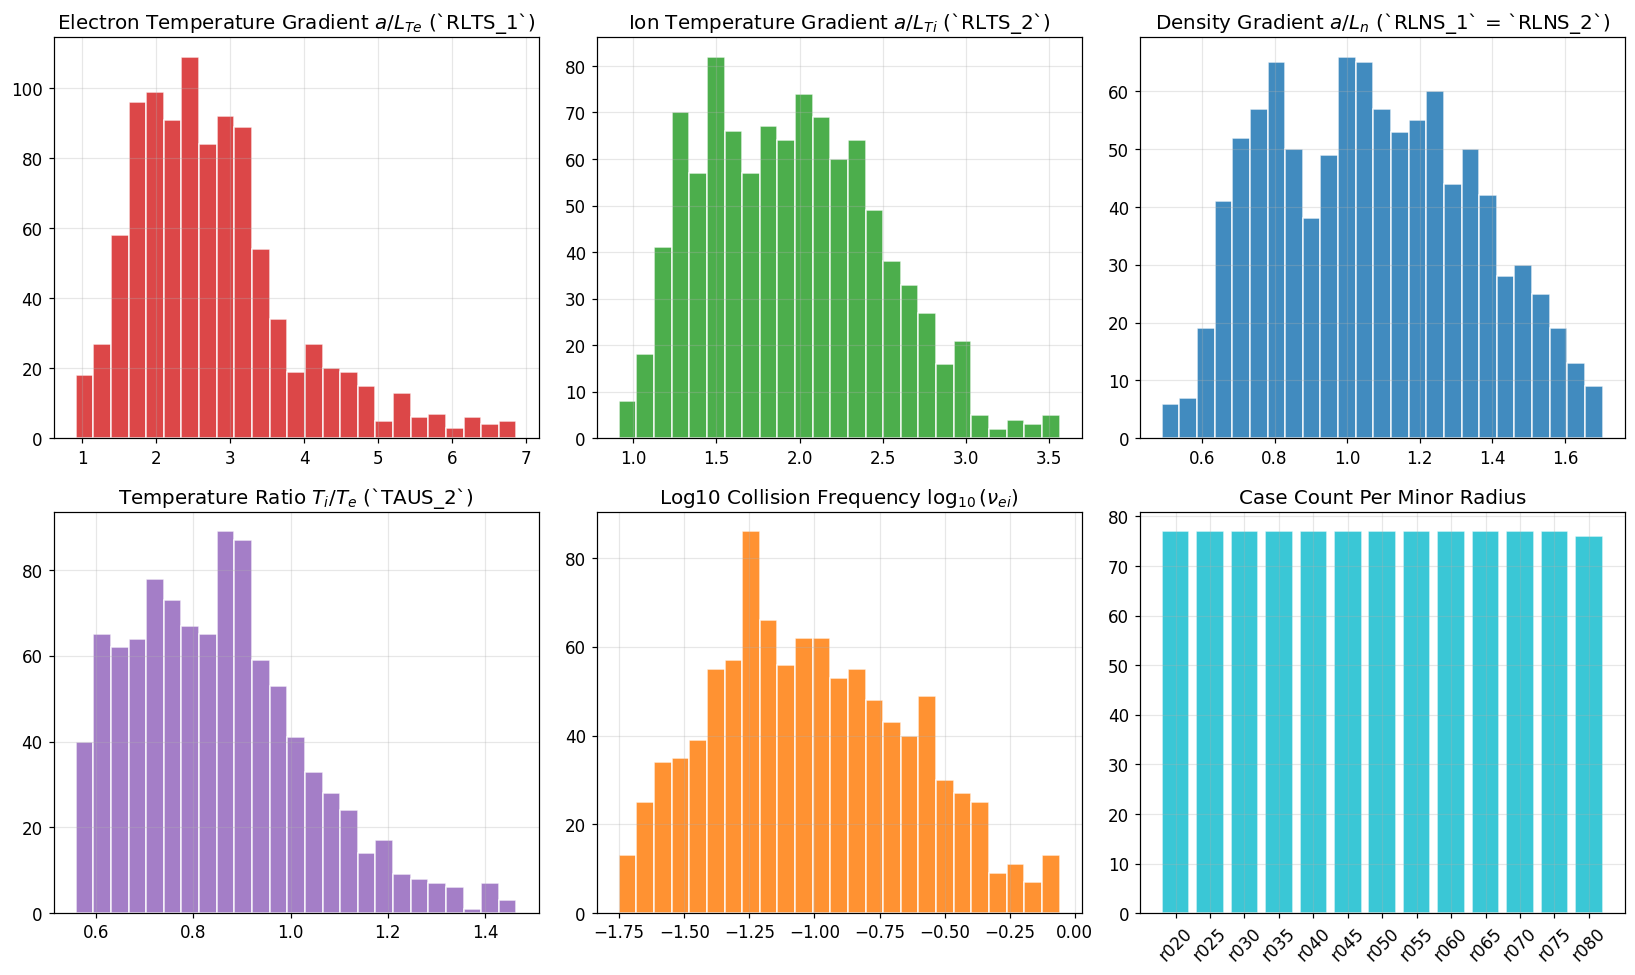

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

axes[0, 0].hist(df_cases["RLTS_1"], bins=25, color="#d62728", edgecolor="white", alpha=0.85)
axes[0, 0].set_title(r"Electron Temperature Gradient $a/L_{Te}$ (`RLTS_1`)")
axes[0, 0].grid(True, alpha=0.3)

axes[0, 1].hist(df_cases["RLTS_2"], bins=25, color="#2ca02c", edgecolor="white", alpha=0.85)
axes[0, 1].set_title(r"Ion Temperature Gradient $a/L_{Ti}$ (`RLTS_2`)")
axes[0, 1].grid(True, alpha=0.3)

axes[0, 2].hist(df_cases["RLNS_1"], bins=25, color="#1f77b4", edgecolor="white", alpha=0.85)
axes[0, 2].set_title(r"Density Gradient $a/L_n$ (`RLNS_1` = `RLNS_2`)")
axes[0, 2].grid(True, alpha=0.3)

axes[1, 0].hist(df_cases["TAUS_2"], bins=25, color="#9467bd", edgecolor="white", alpha=0.85)
axes[1, 0].set_title(r"Temperature Ratio $T_i / T_e$ (`TAUS_2`)")
axes[1, 0].grid(True, alpha=0.3)

axes[1, 1].hist(np.log10(df_cases["XNUE"]), bins=25, color="#ff7f0e", edgecolor="white", alpha=0.85)
axes[1, 1].set_title(r"Log10 Collision Frequency $\log_{10}(\nu_{ei})$")
axes[1, 1].grid(True, alpha=0.3)

rad_counts = df_cases["radius"].value_counts().sort_index()
axes[1, 2].bar(rad_counts.index, rad_counts.values, color="#17becf", edgecolor="white", alpha=0.85)
axes[1, 2].set_title("Case Count Per Minor Radius")
axes[1, 2].tick_params(axis="x", rotation=45)
axes[1, 2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## Step 3: Simulation Execution Status

The 1,000 cases were dispatched using parallel workers running with `caffeinate -dimsu` to ensure the simulation continues uninterrupted even if the laptop display sleeps.

Below, we monitor the number of completed TGLF simulation runs.

In [6]:
data_folder = Path("task4_d3d/d3d_mydb_4/data")
finished = list(data_folder.glob("*/tglf_sat2/out.tglf.gbflux"))
total_cases = len(df_cases)
print(f"Completed TGLF simulations: {len(finished)} / {total_cases} ({len(finished) / total_cases * 100:.1f}%)")

Completed TGLF simulations: 1000 / 1000 (100.0%)


## Step 4: Extract Results and Database Table

Once all 1,000 cases complete, this block ingests all `out.tglf.gbflux` files, merges them with `cases.csv`, flags unphysical negative heat fluxes ($Q_i < 0$), and saves the final cleaned database to `d3d_database.csv`.

In [7]:
rows = []
for c_dir in sorted(data_folder.glob("c*")):
    case_name = c_dir.name
    flux_path = c_dir / "tglf_sat2" / "out.tglf.gbflux"
    if flux_path.exists():
        vals = [float(x) for x in flux_path.read_text().split()]
        rows.append({
            "case": case_name,
            "Gamma_e": vals[0],
            "Gamma_i": vals[1],
            "Q_e": vals[2],
            "Q_i": vals[3],
            "Pi_e": vals[4],
            "Pi_i": vals[5]
        })

df_flux = pd.DataFrame(rows)
if not df_flux.empty:
    df_merged = pd.merge(df_cases, df_flux, on="case")
    df_merged["valid_heat_flux"] = (df_merged["Q_i"] > 0) & (df_merged["Q_e"] > 0)
    df_merged.to_csv("task4_d3d/d3d_database.csv", index=False)
    print(f"Successfully processed {len(df_merged)} cases into d3d_database.csv")
    print(f"Valid positive heat flux cases: {df_merged['valid_heat_flux'].sum()} / {len(df_merged)}")
else:
    print(f"Simulation in progress ({len(finished)} cases completed so far). Re-run this cell once complete.")

Successfully processed 1000 cases into d3d_database.csv
Valid positive heat flux cases: 994 / 1000
